In [34]:
import pandas as pd
import seaborn as sns

penguins = sns.load_dataset('penguins')

In [35]:
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


In [36]:
penguins.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [37]:
penguins.isnull().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

In [38]:
penguins = penguins.dropna(subset=['bill_length_mm', 'sex'])

In [39]:
penguins.isnull().sum()

species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

In [ ]:
X = penguins.drop(columns=['species'])
y = penguins['species']

In [ ]:
y.unique()

array(['Adelie', 'Chinstrap', 'Gentoo'], dtype=object)

In [ ]:
X.head()

,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Torgersen,39.3,20.6,190.0,3650.0,Male


In [ ]:
X_ready = pd.get_dummies(X, columns = ['island', 'sex'], drop_first= True)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_ready, y, test_size=0.2, random_state=42)

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

dummi = DummyClassifier(strategy='most_frequent')
dummi.fit(X_train, y_train)

y_pred = dummi.predict(X_test)

acc = accuracy_score(y_test, y_pred)

print(f'Точность dummi модели {acc:.5f}')

Точность dummi модели 0.46269


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

pipelene = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])

pipelene.fit(X_train, y_train)

,steps,"[('scaler', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [ ]:
y_pred = pipelene.predict(X_test)
y_proba = pipelene.predict_proba(X_test)

In [ ]:
from sklearn.metrics import classification_report

In [ ]:
print(classification_report(y_test, y_pred, target_names=['Adelie', 'Chinstrap', 'Gentoo']))

              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        31
   Chinstrap       1.00      1.00      1.00        13
      Gentoo       1.00      1.00      1.00        23

    accuracy                           1.00        67
   macro avg       1.00      1.00      1.00        67
weighted avg       1.00      1.00      1.00        67



Матрица ошибок (числа):
 [[31  0  0]
 [ 0 13  0]
 [ 0  0 23]]


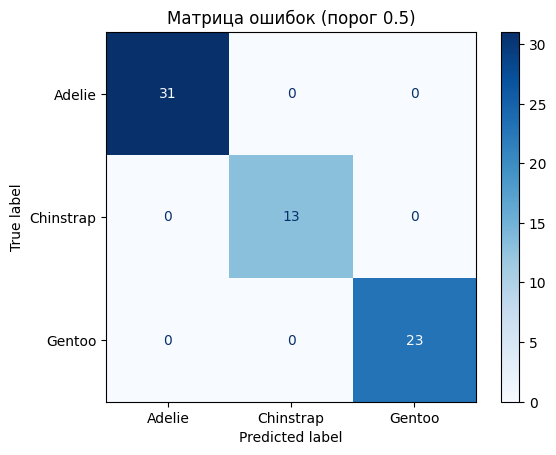

In [42]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Считаем матрицу ошибок на основе предсказаний y_pred (из Day 10)
cm = confusion_matrix(y_test, y_pred)
print("Матрица ошибок (числа):\n", cm)

# Рисуем ее красиво
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Adelie', 'Chinstrap', 'Gentoo'])
disp.plot(cmap='Blues')
plt.title('Матрица ошибок (порог 0.5)')
plt.show()

In [43]:
penguins_dummi = pd.get_dummies(penguins, columns = ['island', 'sex', 'species'], drop_first= True)

In [45]:
penguins.groupby('species')[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']].mean()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.823973,18.347260,190.102740,3706.164384
Chinstrap,48.833824,18.420588,195.823529,3733.088235
Gentoo,47.568067,14.996639,217.235294,5092.436975


In [ ]:
correlations = penguins_dummi.corr()['species'].sort_values(ascending=False)

print("=== ТОП-3 положительных (увеличивают шанс выжить) ===")
print(correlations.head(4)) # head(4), потому что первым будет сам survived (1.0)

print("\n=== ТОП-3 отрицательных (уменьшают шанс выжить) ===")
print(correlations.tail(3))

KeyError: 'species'